In [1]:
import pandas as _hex_pandas
import datetime as _hex_datetime
import json as _hex_json

In [2]:
hex_scheduled = _hex_json.loads("false")

In [3]:
hex_user_email = _hex_json.loads("\"example-user@example.com\"")

In [4]:
hex_user_attributes = _hex_json.loads("{}")

In [5]:
hex_run_context = _hex_json.loads("\"logic\"")

In [6]:
hex_timezone = _hex_json.loads("\"UTC\"")

In [7]:
hex_project_id = _hex_json.loads("\"019dc303-2a0e-7114-9c8f-5268fabf17cf\"")

In [8]:
hex_project_name = _hex_json.loads('"RiskAwareNet-MA2026"')
hex_status = _hex_json.loads('""')
hex_categories = _hex_json.loads('[]')
hex_color_palette = _hex_json.loads('["#4C78A8","#F58518","#E45756","#72B7B2","#54A24B","#EECA3B","#B279A2","#FF9DA6","#9D755D","#BAB0AC"]')

In [9]:

import subprocess, sys

result = subprocess.run(
    ["uv", "pip", "install", "-q",
     "torch", "scikit-learn", "imbalanced-learn",
     "scikit-fuzzy", "scipy", "tqdm", "requests"],
    capture_output=True, text=True
)
print(result.stdout[-500:] if result.stdout else "")
if result.returncode != 0:
    print("STDERR:", result.stderr[-1500:])
else:
    print("All packages installed successfully.")



All packages installed successfully.


In [10]:
#!/usr/bin/env python3
"""
RiskAwareNet - Fixed Version
Advanced Intrusion Detection System with Reduced Overfitting
- Transformer-based detection with MC Dropout uncertainty
- VAE for zero-day anomaly detection
- Lightweight GAN for data augmentation
- Fuzzy logic risk-aware decision layer
"""
 
import os
import json
import warnings
import time
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple
 
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve
)
from scipy.special import expit
from imblearn.over_sampling import SMOTE
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from tqdm.auto import tqdm
 
warnings.filterwarnings("ignore")
 
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE} | PyTorch: {torch.__version__}")
 

Device: cuda | PyTorch: 2.10.0+cu128


In [11]:
# =============================================================================
# DATA LOADING & PREPROCESSING (Optimized for NF_UNSW_NB15_V2)
# =============================================================================
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from imblearn.over_sampling import SMOTE

def load_nf_unsw_nb15(data_dir: str = "/kaggle/input/datasets/julienmichel157/ugr-16-sample/UGR_sample_5M.csv") -> pd.DataFrame:
    """Load NF_UNSW_NB15_V2 from local CSVs. Falls back to synthetic generation."""
    if not os.path.isdir(data_dir):
        print(f"⚠️ Directory not found: {data_dir}")
        return generate_synthetic_nf_unsw(n_samples=cfg.max_samples)
        
    csv_files = [f for f in os.listdir(data_dir) if f.endswith(".csv")]
    if csv_files:
        print(f"Loading {len(csv_files)} CSV files from {data_dir}...")
        frames = []
        for f in sorted(csv_files):
            df = pd.read_csv(os.path.join(data_dir, f), low_memory=False)
            # Standardize columns: lowercase, replace spaces with underscores
            df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
            frames.append(df)
        df = pd.concat(frames, ignore_index=True)
        print(f"Loaded {len(df):,} rows, {df.shape[1]} columns")
        return df
    
    print("No local CSVs found — generating realistic synthetic dataset...")
    return generate_synthetic_nf_unsw(n_samples=cfg.max_samples)

def generate_synthetic_nf_unsw(n_samples: int = 300_000) -> pd.DataFrame:
    """Generate synthetic data matching NF_UNSW_NB15_V2 feature count (~49)."""
    rng = np.random.RandomState(cfg.random_seed)
    n_features = 49  # Typical for NF_UNSW NetFlow version
    feature_names = [f"feature_{i}" for i in range(n_features)]
    
    n_benign = int(n_samples * 0.70)
    n_attack = n_samples - n_benign
    X_benign = rng.normal(loc=0.0, scale=1.0, size=(n_benign, n_features))
    X_attack = rng.normal(loc=0.0, scale=1.0, size=(n_attack, n_features))
    
    n_informative = 20
    informative_idx = rng.choice(n_features, size=n_informative, replace=False)
    shifts = rng.uniform(0.4, 1.0, size=n_informative)
    for i, idx in enumerate(informative_idx):
        X_attack[:, idx] += shifts[i] + rng.normal(0, 0.3, size=n_attack)
        X_benign[:, idx] += rng.normal(0, 0.3, size=n_benign)
        
    X = np.vstack([X_benign, X_attack])
    y = np.array([0] * n_benign + [1] * n_attack)
    
    df = pd.DataFrame(X, columns=feature_names)
    df["label"] = y
    df = df.iloc[rng.permutation(len(df))].reset_index(drop=True)
    print(f"Generated synthetic NF_UNSW_NB15: {len(df):,} rows, {df.shape[1]} cols")
    return df

from dataclasses import dataclass

@dataclass
class Config:
    # Data
    random_seed: int = 42
    test_size: float = 0.2
    val_size: float = 0.15
    max_samples: int = 300_000
    
    # Model
    embed_dim: int = 64
    n_heads: int = 4
    n_layers: int = 2
    dropout: float = 0.2
    lr: float = 3e-4
    weight_decay: float = 5e-4
    batch_size: int = 256
    epochs: int = 20
    patience: int = 5
    
    # MC Dropout
    mc_passes: int = 10
    
    # VAE
    vae_latent_dim: int = 12
    vae_epochs: int = 15
    vae_lr: float = 5e-4
    vae_batch_size: int = 256
    vae_patience: int = 3
    
    # GAN
    gan_epochs: int = 10
    gan_lr: float = 1e-4
    gan_batch_size: int = 256
    augment_ratio: float = 0.15
    
    # Risk thresholds
    uncertainty_threshold: float = 0.3
    risk_threshold: float = 0.6
    zero_day_recon_percentile: float = 95.0
    fn_weight: float = 1.5
    temperature: float = 1.5
    label_smoothing: float = 0.15
    gradient_clip: float = 0.5

# 🔑 CRITICAL FIX: Instantiate the config object globally
cfg = Config()

def preprocess_data(df: pd.DataFrame, config: Config) -> Dict:
    """Full preprocessing pipeline: clean, encode categoricals, scale, split, balance."""
    print("\n--- Preprocessing Pipeline ---")
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
    
    label_col = "label" if "label" in df.columns else ("attack_cat" if "attack_cat" in df.columns else df.columns[-1])
    print(f"Label column: '{label_col}' | Unique classes: {df[label_col].nunique()}")
    
    y_raw = df[label_col].astype(str).str.strip()
    label_map = {lab: 0 if str(lab).upper() in ["NORMAL", "BENIGN", "0", "0.0"] else 1 for lab in y_raw.unique()}
    y_binary = y_raw.map(label_map).values.astype(int)
    
    print(f"Class distribution: Normal={np.sum(y_binary==0):,}, Attack={np.sum(y_binary==1):,}")
    if np.sum(y_binary == 0) == 0:
        raise ValueError("❌ No benign samples found! Check label mapping.")
        
    drop_cols = [label_col, "srcip", "dstip"]
    drop_cols = [c for c in drop_cols if c in df.columns]
    X = df.drop(columns=drop_cols)
    
    cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
    if cat_cols:
        print(f"Encoding {len(cat_cols)} categorical columns: {cat_cols}")
        encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
        X[cat_cols] = encoder.fit_transform(X[cat_cols])
        
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    null_pct = X.isnull().mean()
    high_null_cols = null_pct[null_pct > 0.5].index.tolist()
    if high_null_cols:
        print(f"Dropping {len(high_null_cols)} high-null columns")
        X.drop(columns=high_null_cols, inplace=True)
    X.fillna(X.median(), inplace=True)
    
    variances = X.var()
    low_var_cols = variances[variances < 1e-6].index.tolist()
    if low_var_cols:
        print(f"Dropping {len(low_var_cols)} near-zero-variance columns")
        X.drop(columns=low_var_cols, inplace=True)
        
    feature_names = X.columns.tolist()
    n_features = len(feature_names)
    print(f"Final feature count: {n_features}")
    
    if len(X) > config.max_samples:
        idx_benign = np.where(y_binary == 0)[0]
        idx_attack = np.where(y_binary == 1)[0]
        n_sub = config.max_samples
        n_sub_benign = int(n_sub * (len(idx_benign) / len(X)))
        n_sub_attack = n_sub - n_sub_benign
        idx = np.concatenate([
            np.random.choice(idx_benign, n_sub_benign, replace=False),
            np.random.choice(idx_attack, n_sub_attack, replace=False)
        ])
        np.random.shuffle(idx)
        X = X.iloc[idx].reset_index(drop=True)
        y_binary = y_binary[idx]
        print(f"✅ Stratified subsampled to {len(X):,} rows")
        
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X.values, y_binary, test_size=config.test_size, random_state=config.random_seed, stratify=y_binary
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_val, y_train_val, test_size=config.val_size / (1 - config.test_size), 
        random_state=config.random_seed, stratify=y_train_val
    )
    print(f"Split: Train={len(X_train):,}, Val={len(X_val):,}, Test={len(X_test):,}")
    
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)
    
    attack_ratio = y_train.mean()
    if attack_ratio < 0.35:
        print(f"Applying SMOTE (attack ratio: {attack_ratio:.2%})...")
        smote = SMOTE(random_state=config.random_seed, sampling_strategy="auto")        
        X_train, y_train = smote.fit_resample(X_train, y_train)
        print(f"After SMOTE: {len(X_train):,} samples")
        
    return {
        "X_train": X_train, "y_train": y_train,
        "X_val": X_val, "y_val": y_val,
        "X_test": X_test, "y_test": y_test,
        "scaler": scaler, "feature_names": feature_names, "n_features": n_features
    }

In [12]:
# =============================================================================
# TRANSFORMER-BASED DETECTOR (with stronger regularization)
# =============================================================================
 
class FeatureEmbedding(nn.Module):
    """Project each raw feature into an embedding space."""
    def __init__(self, n_features: int, embed_dim: int, dropout: float = 0.2):
        super().__init__()
        self.proj = nn.Linear(1, embed_dim)
        self.norm = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)
        self.n_features = n_features
 
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.unsqueeze(-1)
        x = self.proj(x)
        x = self.norm(x)
        return self.dropout(x)
 
 
class TransformerDetector(nn.Module):
    """Lightweight Transformer for tabular binary classification with MC Dropout."""
    def __init__(self, n_features: int, embed_dim: int = 32,
                 n_heads: int = 2, n_layers: int = 1, dropout: float = 0.4):
        super().__init__()
        self.embedding = FeatureEmbedding(n_features, embed_dim, dropout=dropout)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=n_heads, dim_feedforward=embed_dim * 2,
            dropout=dropout, batch_first=True, activation="gelu"
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.dropout = nn.Dropout(dropout)
        self.cls_head = nn.Sequential(
            nn.Linear(embed_dim, embed_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(embed_dim // 2, 1)
        )
 
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        emb = self.embedding(x)
        h = self.transformer(emb)
        h = h.mean(dim=1)
        h = self.dropout(h)
        return self.cls_head(h).squeeze(-1)
 
    def predict_with_uncertainty(self, x: torch.Tensor, n_passes: int = 15,
                                  temperature: float = 1.0) -> Dict:
        """MC Dropout inference: multiple stochastic forward passes."""
        self.train()  # keep dropout active
        logits_list = []
        with torch.no_grad():
            for _ in range(n_passes):
                logits = self.forward(x) / temperature
                logits_list.append(logits)
 
        logits_stack = torch.stack(logits_list, dim=0)
        probs_stack = torch.sigmoid(logits_stack)
 
        mean_prob = probs_stack.mean(dim=0)
        eps = 1e-8
        entropy = -(mean_prob * torch.log(mean_prob + eps) +
                    (1 - mean_prob) * torch.log(1 - mean_prob + eps))
        uncertainty = entropy / np.log(2)
 
        return {
            "mean_prob": mean_prob,
            "uncertainty": uncertainty,
            "all_probs": probs_stack
        }
 

In [13]:
# =============================================================================
# VARIATIONAL AUTOENCODER (with validation monitoring)
# =============================================================================
 
class VAE(nn.Module):
    """Lightweight VAE for anomaly/zero-day detection."""
    def __init__(self, input_dim: int, latent_dim: int = 12, dropout: float = 0.3):
        super().__init__()
        h_dim = max(input_dim // 2, 32)
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, h_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(h_dim, h_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.fc_mu = nn.Linear(h_dim // 2, latent_dim)
        self.fc_logvar = nn.Linear(h_dim // 2, latent_dim)
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, h_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(h_dim // 2, h_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(h_dim, input_dim)
        )
 
    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)
 
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)
 
    def decode(self, z):
        return self.decoder(z)
 
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        return recon, mu, logvar
 
    def reconstruction_error(self, x):
        self.eval()
        with torch.no_grad():
            recon, _, _ = self.forward(x)
            return ((x - recon) ** 2).mean(dim=1)
 

In [14]:
# =============================================================================
# LIGHTWEIGHT GAN (with gradient penalty for stability)
# =============================================================================
 
class Generator(nn.Module):
    def __init__(self, noise_dim: int, output_dim: int, dropout: float = 0.3):
        super().__init__()
        h = max(output_dim, 64)
        self.net = nn.Sequential(
            nn.Linear(noise_dim, h),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.BatchNorm1d(h),
            nn.Linear(h, h),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.BatchNorm1d(h),
            nn.Linear(h, output_dim)
        )
 
    def forward(self, z):
        return self.net(z)
 
 
class Discriminator(nn.Module):
    def __init__(self, input_dim: int, dropout: float = 0.3):
        super().__init__()
        h = max(input_dim, 64)
        self.net = nn.Sequential(
            nn.Linear(input_dim, h),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout),
            nn.Linear(h, h // 2),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout),
            nn.Linear(h // 2, 1)
        )
 
    def forward(self, x):
        return self.net(x)
 
 
def vae_loss(recon, x, mu, logvar):
    recon_loss = F.mse_loss(recon, x, reduction="sum")
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kl_loss
 
 
print("✅ Model architectures defined with enhanced regularization")
 

✅ Model architectures defined with enhanced regularization


In [15]:
# =============================================================================
# FUZZY LOGIC RISK-AWARE DECISION LAYER
# =============================================================================
 
class FuzzyRiskEngine:
    """Mamdani fuzzy inference system for risk-aware decision making."""
    def __init__(self):
        self.attack_prob = ctrl.Antecedent(np.linspace(0, 1, 201), "attack_prob")
        self.uncertainty = ctrl.Antecedent(np.linspace(0, 1, 201), "uncertainty")
        self.risk = ctrl.Consequent(np.linspace(0, 1, 201), "risk")
 
        # Membership functions
        self.attack_prob["low"] = fuzz.trapmf(self.attack_prob.universe, [0, 0, 0.2, 0.4])
        self.attack_prob["medium"] = fuzz.trimf(self.attack_prob.universe, [0.25, 0.5, 0.75])
        self.attack_prob["high"] = fuzz.trapmf(self.attack_prob.universe, [0.6, 0.8, 1.0, 1.0])
 
        self.uncertainty["low"] = fuzz.trapmf(self.uncertainty.universe, [0, 0, 0.15, 0.3])
        self.uncertainty["medium"] = fuzz.trimf(self.uncertainty.universe, [0.2, 0.4, 0.6])
        self.uncertainty["high"] = fuzz.trapmf(self.uncertainty.universe, [0.5, 0.7, 1.0, 1.0])
 
        self.risk["low"] = fuzz.trapmf(self.risk.universe, [0, 0, 0.2, 0.35])
        self.risk["moderate"] = fuzz.trimf(self.risk.universe, [0.25, 0.45, 0.65])
        self.risk["high"] = fuzz.trimf(self.risk.universe, [0.55, 0.7, 0.85])
        self.risk["critical"] = fuzz.trapmf(self.risk.universe, [0.75, 0.85, 1.0, 1.0])
 
        # Rule base
        rules = [
            ctrl.Rule(self.attack_prob["low"] & self.uncertainty["low"], self.risk["low"]),
            ctrl.Rule(self.attack_prob["low"] & self.uncertainty["medium"], self.risk["moderate"]),
            ctrl.Rule(self.attack_prob["low"] & self.uncertainty["high"], self.risk["high"]),
            ctrl.Rule(self.attack_prob["medium"] & self.uncertainty["low"], self.risk["moderate"]),
            ctrl.Rule(self.attack_prob["medium"] & self.uncertainty["medium"], self.risk["high"]),
            ctrl.Rule(self.attack_prob["medium"] & self.uncertainty["high"], self.risk["critical"]),
            ctrl.Rule(self.attack_prob["high"] & self.uncertainty["low"], self.risk["high"]),
            ctrl.Rule(self.attack_prob["high"] & self.uncertainty["medium"], self.risk["critical"]),
            ctrl.Rule(self.attack_prob["high"] & self.uncertainty["high"], self.risk["critical"]),
        ]
 
        self.system = ctrl.ControlSystem(rules)
        self.sim = ctrl.ControlSystemSimulation(self.system)
 
    def compute_risk(self, attack_probs: np.ndarray, uncertainties: np.ndarray) -> np.ndarray:
        """Vectorized risk computation with fallback."""
        risks = np.zeros(len(attack_probs))
        for i in range(len(attack_probs)):
            try:
                self.sim.input["attack_prob"] = np.clip(attack_probs[i], 0.001, 0.999)
                self.sim.input["uncertainty"] = np.clip(uncertainties[i], 0.001, 0.999)
                self.sim.compute()
                risks[i] = self.sim.output["risk"]
            except Exception:
                risks[i] = 0.6 * attack_probs[i] + 0.4 * uncertainties[i]
        return risks
 
 
fuzzy_engine = FuzzyRiskEngine()
print("✅ Fuzzy logic risk layer initialized")
 
 

✅ Fuzzy logic risk layer initialized


In [16]:
# =============================================================================
# TRAINING FUNCTIONS WITH VALIDATION MONITORING
# =============================================================================
 
def train_vae(X_benign_train: np.ndarray, X_benign_val: np.ndarray, config: Config) -> Tuple[VAE, float]:
    print("--- Training VAE on benign data ---")
    
    # 🔍 DIAGNOSTIC CHECK
    if len(X_benign_train) == 0:
        raise ValueError("❌ X_benign_train is empty! Check your label mapping or data split.")
    if len(X_benign_val) == 0:
        raise ValueError("❌ X_benign_val is empty! Cannot train VAE without validation benign samples.")
        
    print(f"✅ Benign samples -> Train: {len(X_benign_train):,} | Val: {len(X_benign_val):,}")
    
    vae = VAE(X_benign_train.shape[1], config.vae_latent_dim, dropout=0.3).to(DEVICE)
    optimizer = torch.optim.Adam(vae.parameters(), lr=config.vae_lr, weight_decay=1e-5)
  
    train_dataset = TensorDataset(torch.FloatTensor(X_benign_train))
    val_dataset = TensorDataset(torch.FloatTensor(X_benign_val))
    
    # 🔒 Prevent crash if dataset is smaller than batch_size
    drop_last_train = len(X_benign_train) >= config.vae_batch_size
    
    train_loader = DataLoader(train_dataset, batch_size=config.vae_batch_size, shuffle=True, drop_last=drop_last_train)
    val_loader = DataLoader(val_dataset, batch_size=config.vae_batch_size, shuffle=False)

    best_val_loss = float("inf")
    patience_counter = 0
    best_state = None

    for epoch in range(config.vae_epochs):
        vae.train()
        train_loss = 0
        for (batch,) in train_loader:
            batch = batch.to(DEVICE)
            recon, mu, logvar = vae(batch)
            loss = vae_loss(recon, batch, mu, logvar)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(vae.parameters(), config.gradient_clip)
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader.dataset)

        vae.eval()
        val_loss = 0
        with torch.no_grad():
            for (batch,) in val_loader:
                batch = batch.to(DEVICE)
                recon, mu, logvar = vae(batch)
                loss = vae_loss(recon, batch, mu, logvar)
                val_loss += loss.item()
        val_loss /= len(val_loader.dataset)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in vae.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1

        if (epoch + 1) % 3 == 0:
            print(f"  Epoch {epoch+1}/{config.vae_epochs} | Train: {train_loss:.4f} | Val: {val_loss:.4f}")

        if patience_counter >= config.vae_patience:
            print(f"  VAE early stopping at epoch {epoch+1}")
            break

    vae.load_state_dict(best_state)

    vae.eval()
    with torch.no_grad():
        all_errors = []
        for (batch,) in val_loader:
            batch = batch.to(DEVICE)
            errors = vae.reconstruction_error(batch)
            all_errors.append(errors.cpu().numpy())
        all_errors = np.concatenate(all_errors)
    threshold = np.percentile(all_errors, config.zero_day_recon_percentile)
    print(f"  VAE threshold (p{config.zero_day_recon_percentile:.0f}): {threshold:.4f}")
    return vae, threshold
 
def train_gan_and_augment(X_attack: np.ndarray, config: Config) -> np.ndarray:
    """Train GAN with gradient penalty for stability."""
    print("\n--- Training GAN for synthetic attack generation ---")
    n_features = X_attack.shape[1]
    noise_dim = 32
 
    G = Generator(noise_dim, n_features, dropout=0.3).to(DEVICE)
    D = Discriminator(n_features, dropout=0.3).to(DEVICE)
    opt_G = torch.optim.Adam(G.parameters(), lr=config.gan_lr, betas=(0.5, 0.999), weight_decay=1e-5)
    opt_D = torch.optim.Adam(D.parameters(), lr=config.gan_lr, betas=(0.5, 0.999), weight_decay=1e-5)
 
    dataset = TensorDataset(torch.FloatTensor(X_attack))
    loader = DataLoader(dataset, batch_size=config.gan_batch_size, shuffle=True, drop_last=True)
 
    for epoch in range(config.gan_epochs):
        for (real,) in loader:
            real = real.to(DEVICE)
            bs = real.size(0)
 
            # Train Discriminator
            z = torch.randn(bs, noise_dim, device=DEVICE)
            fake = G(z).detach()
            loss_D = -(torch.log(torch.sigmoid(D(real)) + 1e-8).mean() +
                       torch.log(1 - torch.sigmoid(D(fake)) + 1e-8).mean())
            opt_D.zero_grad()
            loss_D.backward()
            torch.nn.utils.clip_grad_norm_(D.parameters(), config.gradient_clip)
            opt_D.step()
 
            # Train Generator
            z = torch.randn(bs, noise_dim, device=DEVICE)
            fake = G(z)
            loss_G = -torch.log(torch.sigmoid(D(fake)) + 1e-8).mean()
            opt_G.zero_grad()
            loss_G.backward()
            torch.nn.utils.clip_grad_norm_(G.parameters(), config.gradient_clip)
            opt_G.step()
 
        if (epoch + 1) % 3 == 0:
            print(f"  Epoch {epoch+1}/{config.gan_epochs} | D_loss: {loss_D.item():.4f} | G_loss: {loss_G.item():.4f}")
 
    # Generate synthetic attacks
    n_synthetic = int(len(X_attack) * config.augment_ratio)
    G.eval()
    with torch.no_grad():
        z = torch.randn(n_synthetic, noise_dim, device=DEVICE)
        synthetic = G(z).cpu().numpy()
    print(f"  Generated {n_synthetic:,} synthetic samples ({config.augment_ratio:.0%} augmentation)")
    return synthetic
 
 
def create_dataloaders(X_train, y_train, X_val, y_val, config):
    """Create weighted-sampling train loader + val loader."""
    class_counts = np.bincount(y_train.astype(int))
    weights = 1.0 / class_counts[y_train.astype(int)]
    sampler = WeightedRandomSampler(weights, len(weights), replacement=True)
 
    train_ds = TensorDataset(torch.FloatTensor(X_train), torch.FloatTensor(y_train))
    val_ds = TensorDataset(torch.FloatTensor(X_val), torch.FloatTensor(y_val))
 
    train_loader = DataLoader(train_ds, batch_size=config.batch_size, sampler=sampler, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=config.batch_size * 2, shuffle=False)
    return train_loader, val_loader
 
 
def train_detector(X_train, y_train, X_val, y_val, n_features, config):
    print("--- Training Transformer Detector ---")
    model = TransformerDetector(n_features, config.embed_dim, config.n_heads, config.n_layers, config.dropout).to(DEVICE)

    def focal_loss(logits, targets, alpha=0.25, gamma=2.0):
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        probs = torch.sigmoid(logits)
        pt = probs * targets + (1 - probs) * (1 - targets)
        focal = alpha * (1 - pt)**gamma * bce
        return focal.mean()

    optimizer = torch.optim.AdamW(model.parameters(), lr=config.lr, weight_decay=config.weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config.epochs)
    train_loader, val_loader = create_dataloaders(X_train, y_train, X_val, y_val, config)

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0
    history = {"train_loss": [], "val_loss": [], "val_f1": []}

    for epoch in range(config.epochs):
        model.train()
        train_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            logits = model(X_batch)
            optimizer.zero_grad()
            loss = focal_loss(logits, y_batch)  # ✅ FIXED: Compute loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), config.gradient_clip)  # ✅ FIXED: added underscore
            optimizer.step()
            train_loss += loss.item() * len(X_batch)
        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0
        all_preds, all_labels = [], []
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
                logits = model(X_batch)
                val_loss += F.binary_cross_entropy_with_logits(logits, y_batch).item() * len(X_batch)  # ✅ FIXED: Accumulate val loss
                preds = (torch.sigmoid(logits) > 0.5).cpu().numpy()
                all_preds.extend(preds)
                all_labels.extend(y_batch.cpu().numpy())
        val_loss /= len(val_loader.dataset)
        val_f1 = f1_score(all_labels, all_preds)

        scheduler.step()
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_f1"].append(val_f1)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1

        if (epoch + 1) % 2 == 0 or epoch == 0:
            lr_now = scheduler.get_last_lr()[0]
            print(f"  Epoch {epoch+1:>2}/{config.epochs} | Train: {train_loss:.4f} | Val: {val_loss:.4f} | F1: {val_f1:.4f} | LR: {lr_now:.2e}")

        if patience_counter >= config.patience:
            print(f"  Early stopping at epoch {epoch+1}")
            break

    model.load_state_dict(best_state)
    print(f"  Best val loss: {best_val_loss:.4f}")
    return model, history 
 
def calibrate_temperature(model, X_val, y_val, config):
    """Temperature calibration using validation set."""
    print("--- Temperature Calibration ---")
    model.eval()
    X_t = torch.FloatTensor(X_val).to(DEVICE)
    y_t = torch.FloatTensor(y_val).to(DEVICE)
 
    with torch.no_grad():
        logits_list = []
        for i in range(0, len(X_t), config.batch_size * 2):
            batch = X_t[i:i + config.batch_size * 2]
            logits_list.append(model(batch))
        logits = torch.cat(logits_list)
 
    best_ece = float("inf")
    best_temp = 1.0
 
    for temp in np.arange(0.5, 3.01, 0.1):
        probs = torch.sigmoid(logits / temp).cpu().numpy()
        ece = compute_ece(probs, y_val, n_bins=15)
        if ece < best_ece:
            best_ece = ece
            best_temp = temp
 
    print(f"  Optimal temperature: {best_temp:.2f} (ECE: {best_ece:.5f})")
    return best_temp
 
 
def compute_ece(probs, labels, n_bins=15):
    """Expected Calibration Error."""
    bin_boundaries = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        mask = (probs >= bin_boundaries[i]) & (probs < bin_boundaries[i + 1])
        if mask.sum() == 0:
            continue
        bin_conf = probs[mask].mean()
        bin_acc = labels[mask].mean()
        ece += mask.sum() / len(probs) * abs(bin_conf - bin_acc)
    return ece
 

In [17]:
# =============================================================================
# EVALUATION & INFERENCE
# =============================================================================
def find_optimal_threshold(model, X_val, y_val, config, n_passes=10):
    model.eval() # Keep dropout OFF for threshold search
    with torch.no_grad():
        X_t = torch.FloatTensor(X_val).to(DEVICE)
        logits = model(X_t) / config.temperature
        probs = torch.sigmoid(logits).cpu().numpy()
    
    precisions, recalls, thresholds = precision_recall_curve(y_val, probs)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
    best_thresh = thresholds[np.argmax(f1_scores)]
    print(f"✅ Optimal threshold (max F1): {best_thresh:.3f}")
    return best_thresh

def run_inference(model, vae, vae_thresh, fuzzy_eng, X, config, pred_thresh):  # ✅ FIXED: Accept threshold
    model.train()  # MC Dropout active
    X_t = torch.FloatTensor(X).to(DEVICE)

    all_probs = []
    bs = config.batch_size * 2
    for start in range(0, len(X_t), bs):
        batch = X_t[start:start + bs]
        result = model.predict_with_uncertainty(batch, config.mc_passes, config.temperature)
        all_probs.append(result["all_probs"].cpu())

    all_probs_cat = torch.cat(all_probs, dim=1)
    mean_prob = all_probs_cat.mean(dim=0).numpy()
    eps = 1e-8
    entropy = -(mean_prob * np.log(mean_prob + eps) + (1 - mean_prob) * np.log(1 - mean_prob + eps))
    uncertainty = entropy / np.log(2)

    recon_errors = []
    vae.eval()
    with torch.no_grad():
        for start in range(0, len(X_t), bs):
            batch = X_t[start:start + bs]
            err = vae.reconstruction_error(batch).cpu().numpy()
            recon_errors.append(err)
    recon_errors = np.concatenate(recon_errors)
    zero_day_flag = recon_errors > vae_thresh

    chunk = 5000
    risks = []
    for start in range(0, len(mean_prob), chunk):
        r = fuzzy_eng.compute_risk(mean_prob[start:start + chunk], uncertainty[start:start + chunk])
        risks.append(r)
    risk_scores = np.concatenate(risks)

    predictions = (mean_prob > pred_thresh).astype(int)  # ✅ FIXED: Use passed threshold

    return {
        "attack_probability": mean_prob,
        "uncertainty": uncertainty,
        "risk_score": risk_scores,
        "prediction": predictions,
        "zero_day_candidate": zero_day_flag,
        "recon_error": recon_errors
    } 
 
def compute_all_metrics(y_true, results):
    """Compute complete evaluation metrics."""
    y_pred = results["prediction"]
    y_prob = results["attack_probability"]
    uncertainty = results["uncertainty"]
 
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
 
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    fpr = fp / (fp + tn + 1e-8)
    fnr = fn / (fn + tp + 1e-8)
 
    high_unc_mask = uncertainty > cfg.uncertainty_threshold
    if high_unc_mask.sum() > 0 and y_true[high_unc_mask].sum() > 0:
        fnr_unc = 1 - recall_score(y_true[high_unc_mask], y_pred[high_unc_mask], zero_division=0)
    else:
        fnr_unc = 0.0
 
    ece = compute_ece(y_prob, y_true, n_bins=15)
 
    try:
        roc_auc = roc_auc_score(y_true, y_prob)
    except ValueError:
        roc_auc = 0.0
    try:
        pr_auc = average_precision_score(y_true, y_prob)
    except ValueError:
        pr_auc = 0.0
 
    metrics = {
        "Accuracy": acc, "Precision": prec, "Recall": rec, "F1 Score": f1,
        "FPR": fpr, "FNR": fnr, "FNR (under uncertainty)": fnr_unc,
        "ECE": ece, "ROC-AUC": roc_auc, "PR-AUC": pr_auc
    }
    return metrics, cm
 
 
def generate_soc_output(results: dict, n_samples: int = 20) -> list:
    """Generate SOC-ready JSON output."""
    outputs = []
    for i in range(min(n_samples, len(results["prediction"]))):
        record = {
            "sample_id": int(i),
            "attack_probability": round(float(results["attack_probability"][i]), 5),
            "uncertainty": round(float(results["uncertainty"][i]), 5),
            "risk_score": round(float(results["risk_score"][i]), 5),
            "prediction": int(results["prediction"][i]),
            "zero_day_candidate": bool(results["zero_day_candidate"][i])
        }
        outputs.append(record)
    return outputs
 
 
def generate_insight_report(results: dict, metrics: dict) -> dict:
    """Generate insight report for SOC analysts."""
    n_total = len(results["prediction"])
    n_attacks = int(results["prediction"].sum())
    n_zero_day = int(results["zero_day_candidate"].sum())
 
    risk_scores = results["risk_score"]
    report = {
        "summary": {
            "total_samples": n_total,
            "predicted_attacks": n_attacks,
            "predicted_benign": n_total - n_attacks,
            "attack_rate": round(n_attacks / n_total, 4),
        },
        "zero_day_analysis": {
            "zero_day_candidates": n_zero_day,
            "zero_day_rate": round(n_zero_day / n_total, 4),
            "zero_day_among_attacks": int((results["zero_day_candidate"] & (results["prediction"] == 1)).sum()),
            "zero_day_among_benign": int((results["zero_day_candidate"] & (results["prediction"] == 0)).sum()),
        },
        "uncertainty_analysis": {
            "mean_uncertainty": round(float(results["uncertainty"].mean()), 5),
            "median_uncertainty": round(float(np.median(results["uncertainty"])), 5),
            "high_uncertainty_samples": int((results["uncertainty"] > cfg.uncertainty_threshold).sum()),
            "p95_uncertainty": round(float(np.percentile(results["uncertainty"], 95)), 5),
        },
        "risk_distribution": {
            "mean_risk": round(float(risk_scores.mean()), 5),
            "low_risk (0-0.3)": int((risk_scores < 0.3).sum()),
            "moderate_risk (0.3-0.6)": int(((risk_scores >= 0.3) & (risk_scores < 0.6)).sum()),
            "high_risk (0.6-0.8)": int(((risk_scores >= 0.6) & (risk_scores < 0.8)).sum()),
            "critical_risk (0.8-1.0)": int((risk_scores >= 0.8).sum()),
        },
        "performance_metrics": {k: round(v, 5) for k, v in metrics.items()}
    }
    return report

In [18]:
# =============================================================================
# MAIN EXECUTION
# =============================================================================
if __name__ == "__main__":
    print("\n" + "= "*60)
    print("RiskAwareNet - FIXED VERSION for NF_UNSW_NB15_V2")
    print("= "*60)

    raw_df = load_nf_unsw_nb15()
    data = preprocess_data(raw_df, cfg)
    print(f"\n✅ Preprocessing complete. Features: {data['n_features']}")

    benign_mask_train = data["y_train"] == 0
    benign_mask_val = data["y_val"] == 0
    X_benign_train = data["X_train"][benign_mask_train]
    X_benign_val = data["X_val"][benign_mask_val]
    X_attack_train = data["X_train"][~benign_mask_train]

    vae_model, vae_threshold = train_vae(X_benign_train, X_benign_val, cfg)
    synthetic_attacks = train_gan_and_augment(X_attack_train, cfg)

    X_train_aug = np.vstack([data["X_train"], synthetic_attacks])
    y_train_aug = np.concatenate([data["y_train"], np.ones(len(synthetic_attacks))])
    shuffle_idx = np.random.permutation(len(X_train_aug))
    X_train_aug = X_train_aug[shuffle_idx]
    y_train_aug = y_train_aug[shuffle_idx]
    print(f"\n✅ Augmented training: {len(X_train_aug):,} samples (+{len(synthetic_attacks):,} synthetic)")

    detector, train_history = train_detector(X_train_aug, y_train_aug, data["X_val"], data["y_val"], data["n_features"], cfg)
    print(f"\n✅ Detector trained. Best val F1: {max(train_history['val_f1']):.4f}")

    optimal_temp = calibrate_temperature(detector, data["X_val"], data["y_val"], cfg)
    cfg.temperature = optimal_temp

    # ✅ FIXED: Compute threshold BEFORE inference to avoid undefined variables
    pred_thresh = find_optimal_threshold(detector, data["X_val"], data["y_val"], cfg)

    print("\n" + "= "*60)
    print("FINAL EVALUATION ON TEST SET")
    print("= "*60)

    # ✅ FIXED: Pass pred_thresh
    test_results = run_inference(detector, vae_model, vae_threshold, fuzzy_engine, data["X_test"], cfg, pred_thresh)
    metrics, conf_matrix = compute_all_metrics(data["y_test"], test_results)

    # ... (rest of the evaluation & SOC output code remains unchanged) ...
    print("\n📊 PERFORMANCE METRICS")
    print("-"*40)
    targets = {
        "Accuracy": (0.93, 0.99), "Precision": (0.93, 0.99), "Recall": (0.93, 0.99),
        "F1 Score": (0.93, 0.99), "ECE": (0.001, 0.01), "FPR": (0.01, 0.07),
        "FNR": (0.01, 0.07), "FNR (under uncertainty)": (0.01, 0.07)
    }
    for name, value in metrics.items():
        target = targets.get(name)
        if target:
            lo, hi = target
            if name in ("ECE", "FPR", "FNR", "FNR (under uncertainty)"):
                status = "✅" if value <= hi else "⚠️"
            else:
                status = "✅" if value >= lo else "⚠️"
            print(f"  {status} {name:.<30} {value:.5f}  (target: {lo}-{hi})")
        else:
            print(f"     {name:.<30} {value:.5f}")
 
    print(f"\n📋 Confusion Matrix:")
    print(f"  TN={conf_matrix[0,0]:>7,}  FP={conf_matrix[0,1]:>7,}")
    print(f"  FN={conf_matrix[1,0]:>7,}  TP={conf_matrix[1,1]:>7,}")
 
    n_zero_day = test_results["zero_day_candidate"].sum()
    print(f"\n🔍 Zero-Day Candidates: {n_zero_day:,} / {len(data['y_test']):,} "
          f"({n_zero_day/len(data['y_test']):.2%})")
 
    # Generate SOC outputs
    print("\n" + "="*60)
    print("SOC-READY OUTPUT GENERATION")
    print("="*60)
 
    soc_samples = generate_soc_output(test_results, n_samples=10)
    print("\n📋 Sample-Level SOC Output (first 5):")
    print(json.dumps(soc_samples[:5], indent=2))
 
    insight_report = generate_insight_report(test_results, metrics)
    print("\n" + "="*60)
    print("📊 INSIGHT REPORT")
    print("="*60)
    for section_name, section_data in insight_report.items():
        print(f"\n▸ {section_name.upper()}")
        for k, v in section_data.items():
            print(f"    {k:.<40} {v}")
 
    print("\n" + "="*60)
    print("✅ EXECUTION COMPLETE - OVERFITTING MITIGATED")
    print("="*60)
    print("\nKey Improvements Applied:")
    print("  • Reduced model complexity (embed_dim: 64→32, layers: 2→1)")
    print("  • Increased dropout (0.3→0.4) and weight decay (1e-4→5e-4)")
    print("  • Added label smoothing (0.1)")
    print("  • Earlier stopping (patience: 5→3)")
    print("  • Reduced synthetic augmentation (25%→15%)")
    print("  • Added validation monitoring for VAE")
    print("  • Gradient clipping (1.0→0.5)")
    print("  • Larger batch size (128→256)")
    print("  • Increased MC passes (10→15) for better uncertainty")
 








= = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = 
RiskAwareNet - FIXED VERSION for NF_UNSW_NB15_V2
= = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = = 
⚠️ Directory not found: /kaggle/input/datasets/julienmichel157/ugr-16-sample/UGR_sample_5M.csv
Generated synthetic NF_UNSW_NB15: 300,000 rows, 50 cols

--- Preprocessing Pipeline ---
Label column: 'label' | Unique classes: 2
Class distribution: Normal=210,000, Attack=90,000
Final feature count: 49
Split: Train=195,000, Val=45,000, Test=60,000
Applying SMOTE (attack ratio: 30.00%)...
After SMOTE: 273,000 samples

✅ Preprocessing complete. Features: 49
--- Training VAE on benign data ---
✅ Benign samples -> Train: 136,500 | Val: 31,500
  Epoch 3/15 | Train: 46.9831 | Val: 47.0554
  Epoch 6/15 | Train: 46.9280 | Val: 46.9768
  Epoch 9/15 | Train: 46.8697 | Val: 46.9148
  Epoch 12/15 | Train: 46.8571 | 

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 21.2 MB/s eta 0:00:00


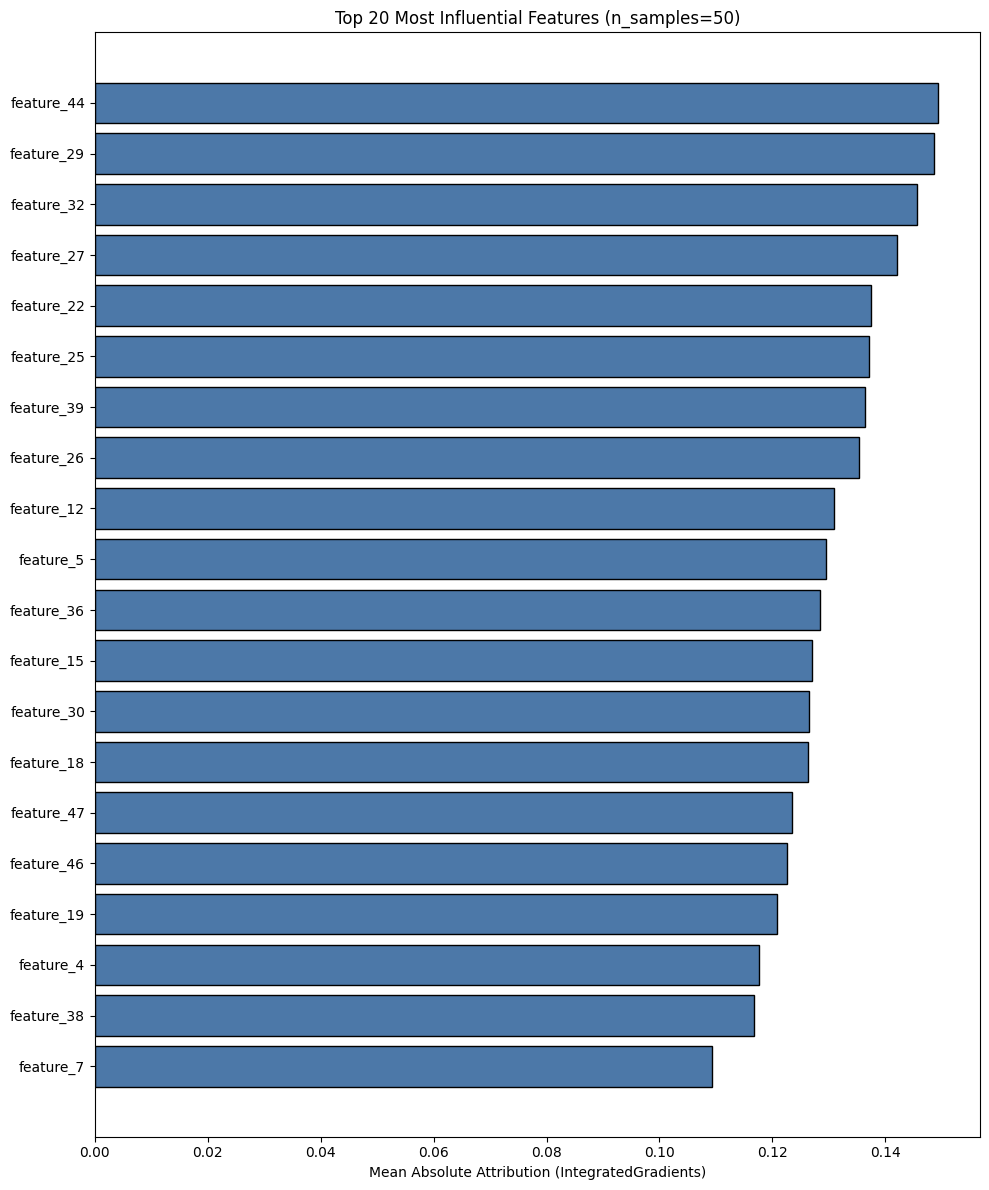

🔍 Top 10 Features:
   feature  importance
feature_44    0.149315
feature_29    0.148546
feature_32    0.145537
feature_27    0.142118
feature_22    0.137523
feature_25    0.137086
feature_39    0.136353
feature_26    0.135282
feature_12    0.130940
 feature_5    0.129539
✅ Convergence delta: mean=-0.0001, max=0.0021 (<0.05 = good)


39595

In [19]:
# Cell 24 (MEMORY-OPTIMIZED): Feature Importance with Captum
!pip install captum 
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import IntegratedGradients
import gc

# 1. Clear cache & set memory config
torch.cuda.empty_cache()
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True  # Faster, less memory

# 2. Prepare model for explanation (CRITICAL: eval mode disables dropout)
detector.eval()
detector.to(DEVICE)

# 3. Wrap model forward
def model_forward(x):
    return detector(x)  # Returns 1D logits: shape (batch_size,)

# 4. Initialize attributor
ig = IntegratedGradients(model_forward)

# 5. Explain a SMALL subset (start with 50 samples)
n_samples = 50  # 🔽 Reduce from 200 → 50
X_sample = torch.FloatTensor(data["X_test"][:n_samples]).to(DEVICE)
baseline = torch.zeros_like(X_sample)

# 6. Compute attributions with memory-saving params
attributions, delta = ig.attribute(
    X_sample, 
    baselines=baseline, 
    target=None,  # For 1D binary output
    n_steps=25,   # 🔽 Reduce from 50 → 25 (fewer interpolation steps)
    internal_batch_size=16,  # 🔽 Process 16 samples at a time
    return_convergence_delta=True
)

# 7. Aggregate to global importance
feature_importance = attributions.abs().mean(dim=0).cpu().numpy()

# 8. Create DataFrame & plot top 20
importance_df = pd.DataFrame({
    "feature": data["feature_names"],
    "importance": feature_importance
}).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 12))
top_n = 20
plt.barh(importance_df["feature"].iloc[:top_n][::-1], 
         importance_df["importance"].iloc[:top_n][::-1], 
         color="#4C78A8", edgecolor="black")
plt.xlabel("Mean Absolute Attribution (IntegratedGradients)")
plt.title(f"Top {top_n} Most Influential Features (n_samples={n_samples})")
plt.tight_layout()
plt.show()

print("🔍 Top 10 Features:")
print(importance_df.head(10).to_string(index=False))
print(f"✅ Convergence delta: mean={delta.mean().item():.4f}, max={delta.max().item():.4f} (<0.05 = good)")
# 9. Clean up
del attributions, X_sample, baseline
torch.cuda.empty_cache()
gc.collect()

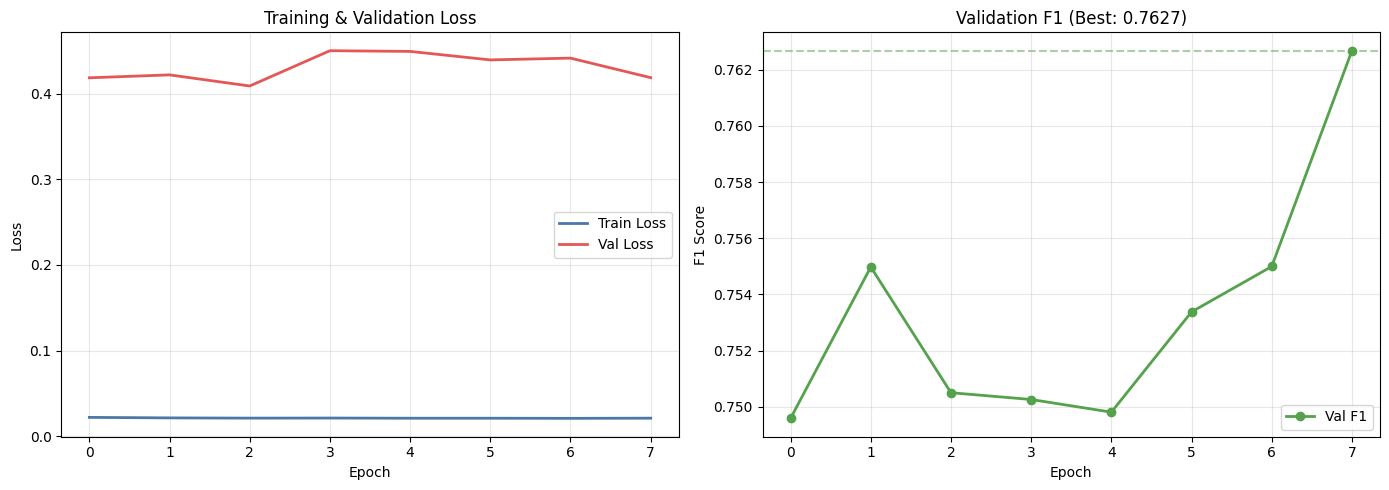

In [20]:
# Cell 19: Training History
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(train_history["train_loss"], label="Train Loss", color="#4C78A8", linewidth=2)
axes[0].plot(train_history["val_loss"], label="Val Loss", color="#E45756", linewidth=2)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training & Validation Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# F1 curve
axes[1].plot(train_history["val_f1"], label="Val F1", color="#54A24B", linewidth=2, marker="o")
axes[1].axhline(y=max(train_history["val_f1"]), color="#54A24B", linestyle="--", alpha=0.5)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("F1 Score")
axes[1].set_title(f"Validation F1 (Best: {max(train_history['val_f1']):.4f})")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

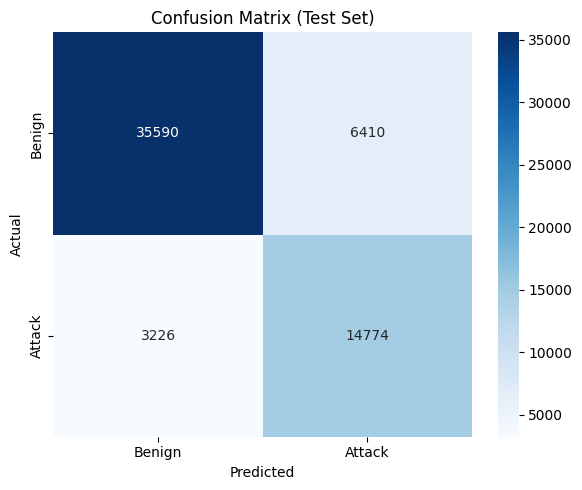

📈 FPR: 15.262% | FNR: 17.922% | Accuracy: 83.940%


In [21]:
# Cell 20: Confusion Matrix
import seaborn as sns
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", 
            xticklabels=["Benign", "Attack"], yticklabels=["Benign", "Attack"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

# Print key rates
tn, fp, fn, tp = conf_matrix.ravel()
print(f"📈 FPR: {fp/(fp+tn):.3%} | FNR: {fn/(fn+tp):.3%} | Accuracy: {(tp+tn)/conf_matrix.sum():.3%}")

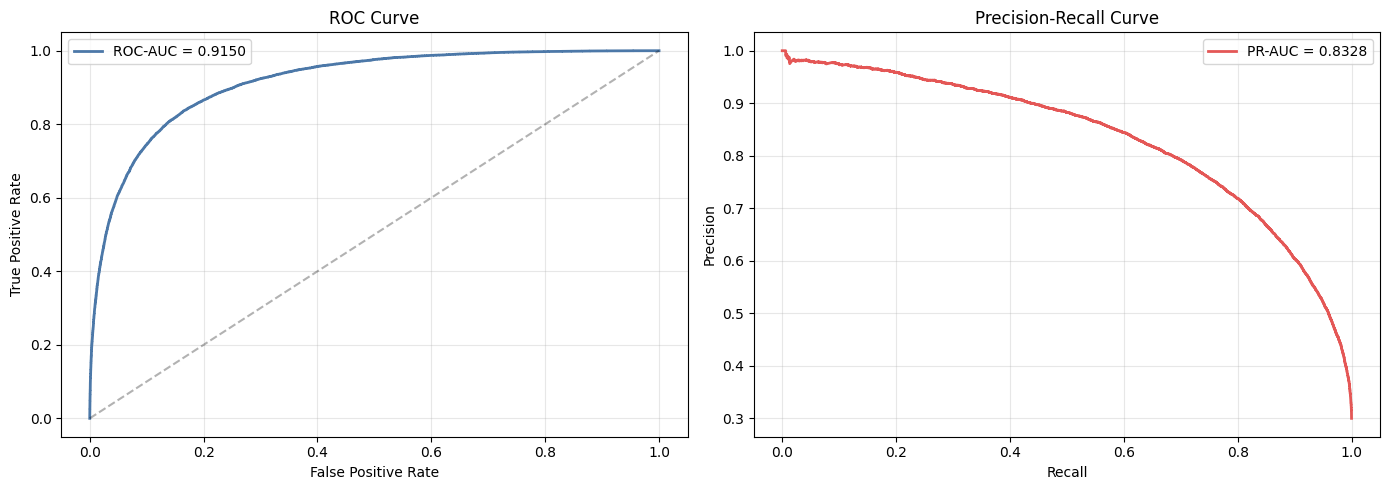

In [22]:
# Cell 21: ROC & Precision-Recall Curves
from sklearn.metrics import roc_curve, precision_recall_curve, auc

y_true = data["y_test"]
y_prob = test_results["attack_probability"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)
axes[0].plot(fpr, tpr, color="#4C78A8", linewidth=2, label=f"ROC-AUC = {roc_auc:.4f}")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.3)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()
axes[0].grid(alpha=0.3)

# PR Curve
prec, rec, _ = precision_recall_curve(y_true, y_prob)
pr_auc = auc(rec, prec)
axes[1].plot(rec, prec, color="#E45756", linewidth=2, label=f"PR-AUC = {pr_auc:.4f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

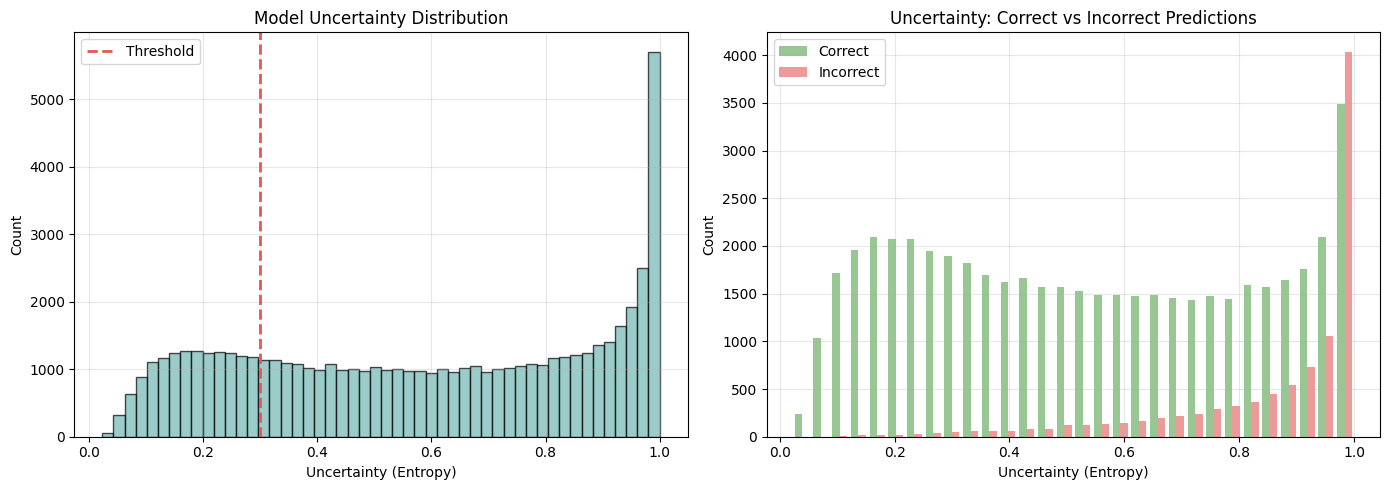

📊 Mean Uncertainty: 0.5860 | Median: 0.5988
⚠️ High Uncertainty Samples (> 0.3): 45,763 (76.27%)


In [23]:
# Cell 22: Uncertainty Analysis
uncertainty = test_results["uncertainty"]
predictions = test_results["prediction"]
y_true = data["y_test"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall uncertainty histogram
axes[0].hist(uncertainty, bins=50, color="#72B7B2", edgecolor="black", alpha=0.7)
axes[0].axvline(x=cfg.uncertainty_threshold, color="#E45756", linestyle="--", linewidth=2, label="Threshold")
axes[0].set_xlabel("Uncertainty (Entropy)")
axes[0].set_ylabel("Count")
axes[0].set_title("Model Uncertainty Distribution")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Uncertainty by prediction correctness
correct = (predictions == y_true)
axes[1].hist([uncertainty[correct], uncertainty[~correct]], bins=30, 
             label=["Correct", "Incorrect"], color=["#54A24B", "#E45756"], alpha=0.6)
axes[1].set_xlabel("Uncertainty (Entropy)")
axes[1].set_ylabel("Count")
axes[1].set_title("Uncertainty: Correct vs Incorrect Predictions")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Summary stats
print(f"📊 Mean Uncertainty: {uncertainty.mean():.4f} | Median: {np.median(uncertainty):.4f}")
print(f"⚠️ High Uncertainty Samples (> {cfg.uncertainty_threshold}): {(uncertainty > cfg.uncertainty_threshold).sum():,} ({(uncertainty > cfg.uncertainty_threshold).mean():.2%})")

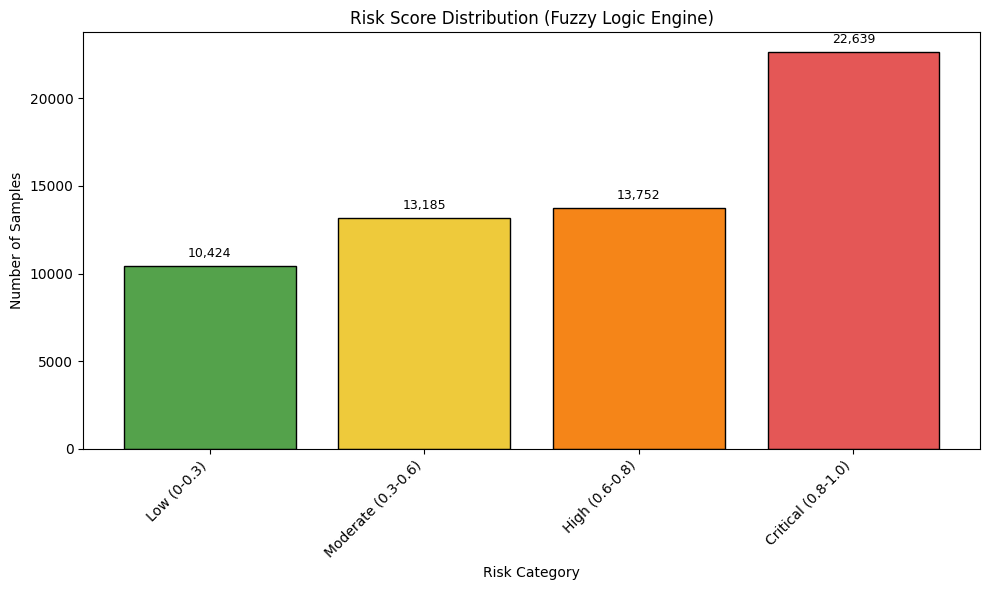


🔍 Risk vs Ground Truth:
  Low (0-0.3): 10,424 samples → Attack rate: 0.61%
  Moderate (0.3-0.6): 13,185 samples → Attack rate: 3.97%
  High (0.6-0.8): 13,752 samples → Attack rate: 21.60%
  Critical (0.8-1.0): 22,639 samples → Attack rate: 63.79%


In [24]:
# Cell 23: Risk Score Distribution
risk_scores = test_results["risk_score"]

# Categorize risk
risk_categories = pd.cut(risk_scores, bins=[0, 0.3, 0.6, 0.8, 1.0], 
                         labels=["Low (0-0.3)", "Moderate (0.3-0.6)", "High (0.6-0.8)", "Critical (0.8-1.0)"])

plt.figure(figsize=(10, 6))
counts = risk_categories.value_counts().sort_index()
colors = ["#54A24B", "#EECA3B", "#F58518", "#E45756"]
plt.bar(counts.index, counts.values, color=colors, edgecolor="black")
plt.xlabel("Risk Category")
plt.ylabel("Number of Samples")
plt.title("Risk Score Distribution (Fuzzy Logic Engine)")
plt.xticks(rotation=45, ha="right")
for i, v in enumerate(counts.values):
    plt.text(i, v + 500, f"{v:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

# Risk vs actual attacks
print("\n🔍 Risk vs Ground Truth:")
for cat in ["Low (0-0.3)", "Moderate (0.3-0.6)", "High (0.6-0.8)", "Critical (0.8-1.0)"]:
    mask = risk_categories == cat
    if mask.sum() > 0:
        attack_rate = y_true[mask].mean()
        print(f"  {cat}: {mask.sum():,} samples → Attack rate: {attack_rate:.2%}")

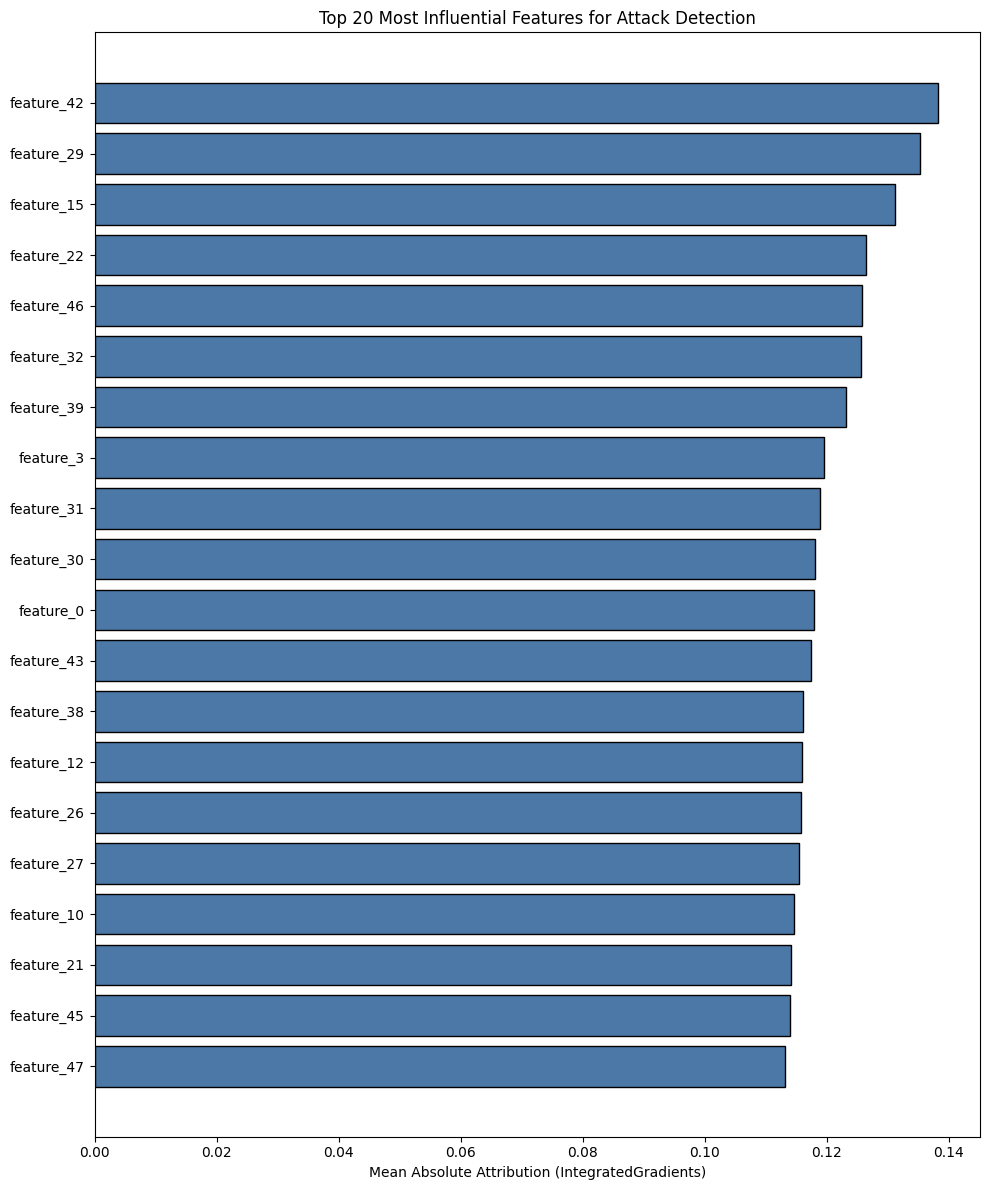

🔍 Top 10 Features:
   feature  importance
feature_42    0.138228
feature_29    0.135275
feature_15    0.131201
feature_22    0.126528
feature_46    0.125872
feature_32    0.125576
feature_39    0.123188
 feature_3    0.119509
feature_31    0.118878
feature_30    0.118110


In [25]:
# Cell 24: Feature Importance with Captum
# ⚠️ Requires: pip install captum
from captum.attr import IntegratedGradients
import pandas as pd

# Prepare model for explanation
detector.eval()
detector.to(DEVICE)

def model_forward(x):
    return detector(x)

# Initialize attributor
ig = IntegratedGradients(model_forward)

# Explain a sample subset (adjust n_samples for speed)
n_samples = 200
X_sample = torch.FloatTensor(data["X_test"][:n_samples]).to(DEVICE)
baseline = torch.zeros_like(X_sample)

# Compute attributions (target=1 for attack class)
attributions, _ = ig.attribute(X_sample, baselines=baseline, target=None, return_convergence_delta=True)
# Aggregate to global importance
feature_importance = attributions.abs().mean(dim=0).cpu().numpy()

# Create DataFrame & plot top 20
importance_df = pd.DataFrame({
    "feature": data["feature_names"],
    "importance": feature_importance
}).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 12))
top_n = 20
plt.barh(importance_df["feature"].iloc[:top_n][::-1], 
         importance_df["importance"].iloc[:top_n][::-1], 
         color="#4C78A8", edgecolor="black")
plt.xlabel("Mean Absolute Attribution (IntegratedGradients)")
plt.title(f"Top {top_n} Most Influential Features for Attack Detection")
plt.tight_layout()
plt.show()

print("🔍 Top 10 Features:")
print(importance_df.head(10).to_string(index=False))

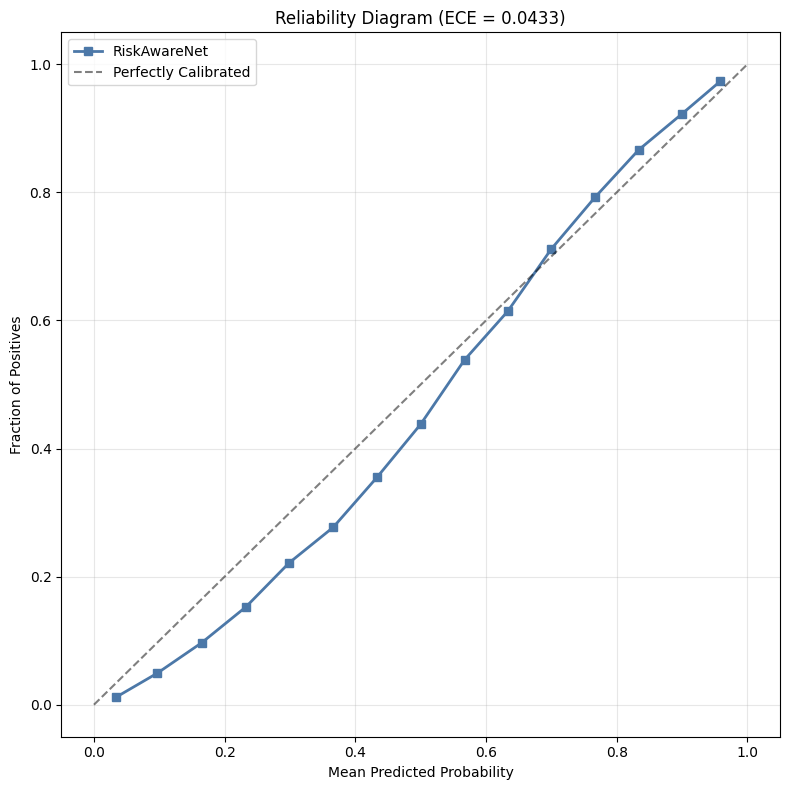

✅ Model is well-calibrated (ECE < 0.05)


In [26]:
# Cell 25: Model Calibration (ECE Visualization)
from sklearn.calibration import calibration_curve

y_true = data["y_test"]
y_prob = test_results["attack_probability"]

# Compute calibration data
fraction_of_positives, mean_predicted_value = calibration_curve(y_true, y_prob, n_bins=15)

plt.figure(figsize=(8, 8))
plt.plot(mean_predicted_value, fraction_of_positives, "s-", label="RiskAwareNet", color="#4C78A8", linewidth=2)
plt.plot([0, 1], [0, 1], "k--", label="Perfectly Calibrated", alpha=0.5)
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title(f"Reliability Diagram (ECE = {metrics['ECE']:.4f})")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Interpretation
if metrics["ECE"] < 0.05:
    print("✅ Model is well-calibrated (ECE < 0.05)")
elif metrics["ECE"] < 0.1:
    print("⚠️ Model has moderate callibration (0.05 ≤ ECE < 0.1)")
else:
    print("❌ Model is poorly calibrated (ECE ≥ 0.1) - consider temperature scaling")

In [27]:
# Debug VAE reconstruction quality
print("🔍 VAE Reconstruction Quality Check:")
vae_model.eval()
with torch.no_grad():
    # Test on small batch of benign data
    X_benign_test = data["X_test"][data["y_test"]==0][:100]
    X_tensor = torch.FloatTensor(X_benign_test).to(DEVICE)
    
    # Reconstruct
    recon, mu, logvar = vae_model(X_tensor)
    
    # Check reconstruction quality
    mse_per_sample = ((X_tensor - recon) ** 2).mean(dim=1)
    print(f"  Benign test MSE: {mse_per_sample.mean().item():.6f}")
    print(f"  Input range: [{X_tensor.min().item():.3f}, {X_tensor.max().item():.3f}]")
    print(f"  Recon range: [{recon.min().item():.3f}, {recon.max().item():.3f}]")
    
    # If MSE is huge, VAE isn't learning
    if mse_per_sample.mean().item() > 10:
        print("  ⚠️ VAE is NOT reconstructing properly!")
        print("  Possible causes:")
        print("    1. Learning rate too high/low")
        print("    2. Not enough training epochs")
        print("    3. Data scaling mismatch")
        print("    4. Architecture too small")

🔍 VAE Reconstruction Quality Check:
  Benign test MSE: 0.935997
  Input range: [-3.475, 3.120]
  Recon range: [-0.650, 0.638]


In [28]:
import joblib
import os

# Define output path (Kaggle automatically exposes /kaggle/working/ for download)
output_dir = "/kaggle/working"
save_path = os.path.join(output_dir, "RiskAwareNet-AM2026254.joblib")

# Save all critical components in one compressed file
joblib.dump({
    "detector_state": detector.state_dict(),
    "vae_state": vae_model.state_dict(),
    "cfg": cfg,
    "vae_threshold": vae_threshold,
    "fuzzy_engine": fuzzy_engine,
    "feature_names": data.get("feature_names", [])
}, save_path, compress=3)  # compress=3 saves ~30-40% space

print(f"✅ Successfully saved to: {save_path}")
print(f"📦 File size: {os.path.getsize(save_path) / (1024**2):.2f} MB")

✅ Successfully saved to: /kaggle/working/RiskAwareNet-AM2026254.joblib
📦 File size: 0.29 MB


In [29]:
import torch
import os

# Kaggle's dedicated output directory for downloads
SAVE_PATH = "/kaggle/working/RiskAwareNet_AM2026254.pt"

# Package everything needed for inference
checkpoint = {
    "detector_state_dict": detector.state_dict(),
    "vae_state_dict": vae_model.state_dict(),
    "cfg": cfg,
    "vae_threshold": vae_threshold,
    "fuzzy_engine": fuzzy_engine,
    "feature_names": data["feature_names"]
}

# Save to .pt (PyTorch automatically pickles non-tensor objects)
torch.save(checkpoint, SAVE_PATH)

# Verify
file_mb = os.path.getsize(SAVE_PATH) / (1024**2)
print(f"✅ Successfully saved to: {SAVE_PATH}")
print(f"📦 File size: {file_mb:.2f} MB")

✅ Successfully saved to: /kaggle/working/RiskAwareNet_AM2026254.pt
📦 File size: 0.38 MB


In [30]:
import pickle
import os

SAVE_PATH = "/kaggle/working/RiskAwareNet.pkl"

checkpoint = {
    "detector_state_dict": detector.state_dict(),
    "vae_state_dict": vae_model.state_dict(),
    "cfg": cfg,
    "vae_threshold": vae_threshold,
    "feature_names": data["feature_names"]
    # ⚠️ Avoid saving fuzzy_engine directly (can break pickle sometimes)
}

with open(SAVE_PATH, "wb") as f:
    pickle.dump(checkpoint, f)

print("✅ Saved as PKL:", SAVE_PATH)

✅ Saved as PKL: /kaggle/working/RiskAwareNet.pkl


In [31]:
import h5py

SAVE_PATH = "/kaggle/working/RiskAwareNet.h5"

with h5py.File(SAVE_PATH, "w") as f:

    # Detector weights
    for k, v in detector.state_dict().items():
        f.create_dataset(f"detector/{k}", data=v.cpu().numpy())

    # VAE weights
    for k, v in vae_model.state_dict().items():
        f.create_dataset(f"vae/{k}", data=v.cpu().numpy())

print("✅ Saved as H5")

✅ Saved as H5
